In [1]:
%pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.svm import SVR
from xgboost import XGBRegressor

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
X_train = pd.read_csv('X_train_sel.csv')
X_test = pd.read_csv('X_test_sel.csv')
y_train = pd.read_csv('y_train_sel.csv')
y_test = pd.read_csv('y_test_sel.csv')

# Drop sn
X_train = X_train.drop('sn', axis=1)
X_test = X_test.drop('sn', axis=1)

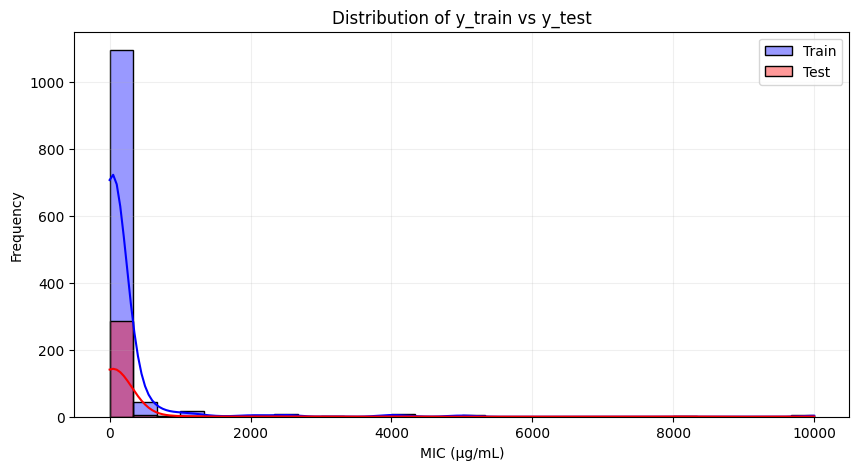

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(y_train.squeeze(), bins=30, color='blue',
             label='Train', alpha=0.4, kde=True)

sns.histplot(y_test.squeeze(), bins=30, color='red',
             label='Test', alpha=0.4, kde=True)

plt.xlabel('MIC (µg/mL)')
plt.ylabel('Frequency')
plt.title('Distribution of y_train vs y_test')
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [5]:
# Identify feature types
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [6]:
# Preprocessing
numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [7]:
models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Lasso': Lasso(
        alpha=0.1,
        max_iter=10000
    ),

    'XGBoost': XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    'SVR': SVR(
        kernel='rbf',
        C=10,
        epsilon=0.1,
        gamma='scale'
    )
}

In [8]:
results = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)

    # Ensure positive MIC predictions
    pred = np.maximum(pred, 0.000001)

    results[name] = pipeline
    predictions[name] = pred

    print(f"{name}: Training completed")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest: Training completed
Lasso: Training completed
XGBoost: Training completed
SVR: Training completed


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [9]:
evaluation = []

for name, pred in predictions.items():

    evaluation.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mean_squared_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

evaluation_df = pd.DataFrame(evaluation)
evaluation_df = evaluation_df.sort_values('RMSE', ascending=True)
print(evaluation_df)

           Model         MAE            MSE        RMSE        R2
2        XGBoost  109.258003  324731.906250  569.852530  0.490305
1          Lasso  133.044903  356278.262690  596.890495  0.440791
0  Random Forest  122.258758  486658.862221  697.609391  0.236147
3            SVR  151.412994  654898.294377  809.257866 -0.027919


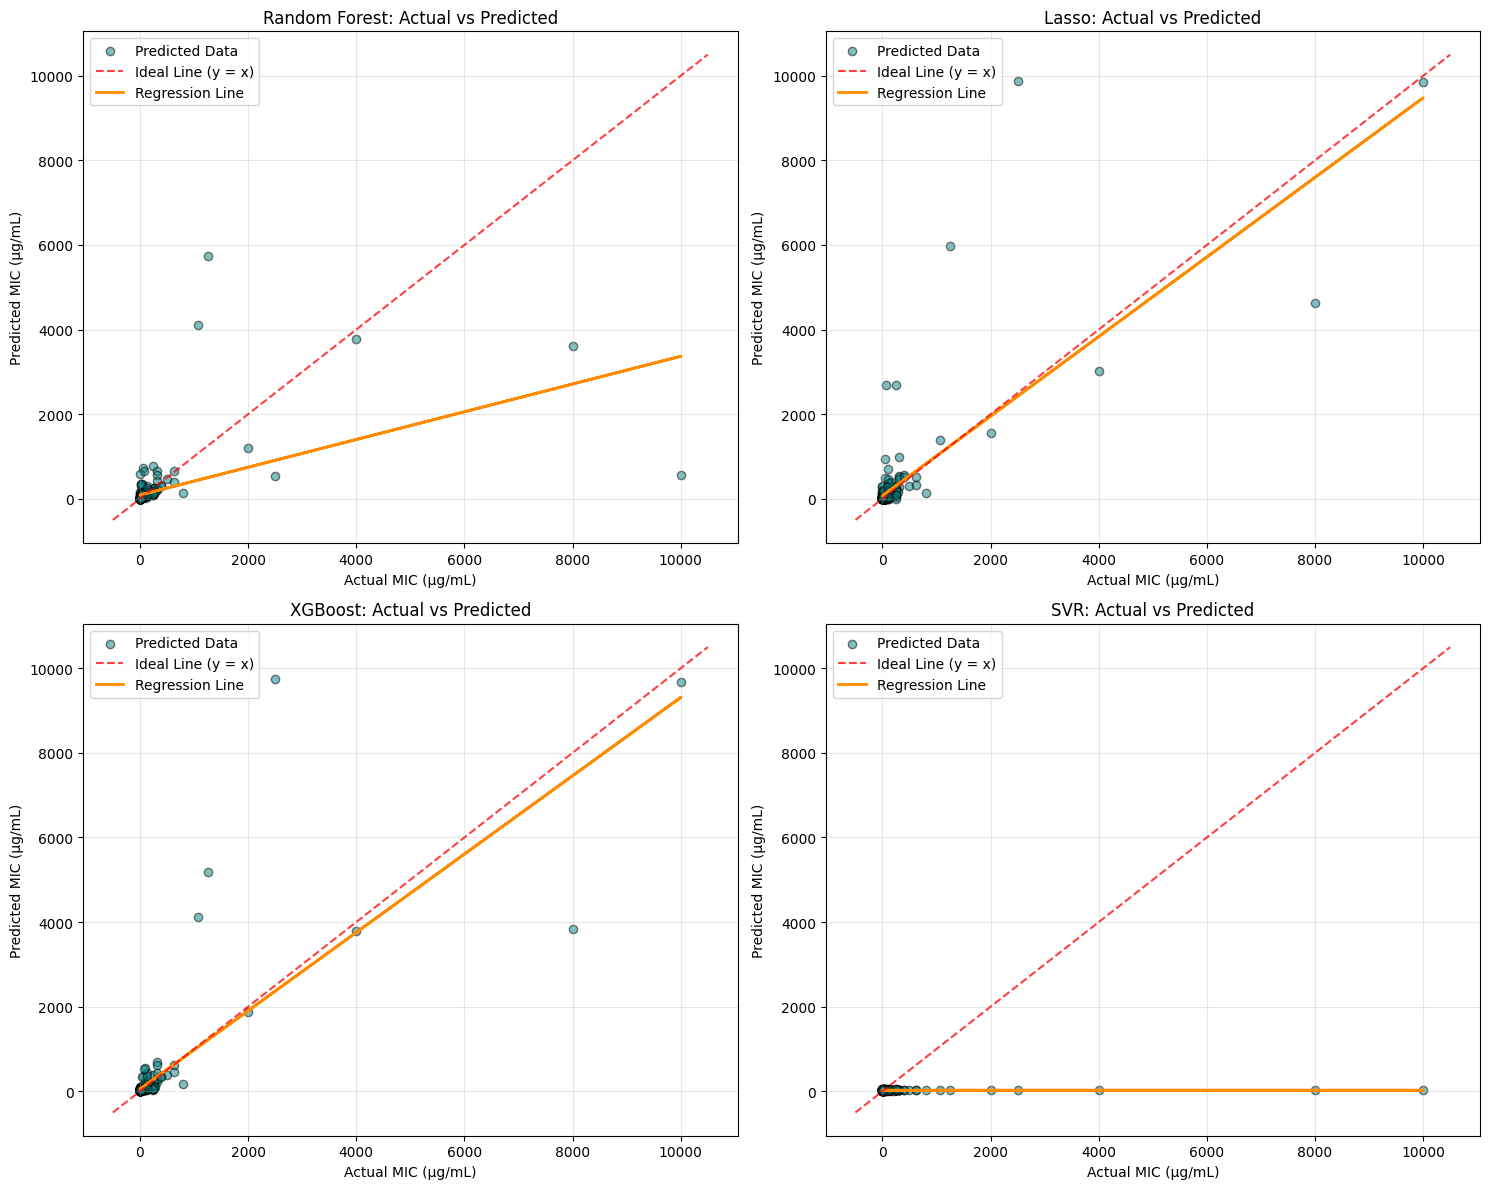

In [10]:
# Set up the subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

y_actual = y_test.squeeze()

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes[idx]
    # Plot actual vs predicted values
    ax.scatter(y_actual, pred, alpha=0.5, color='teal', edgecolors='k', label='Predicted Data')
    # Plot the ideal line (y = x)
    lims = [
        np.min([ax.get_xlim(), ax.get_ylim()]),
        np.max([ax.get_xlim(), ax.get_ylim()])
    ]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=3, label='Ideal Line (y = x)')
    # Plot the actual regression line
    m, b = np.polyfit(y_actual, pred, 1)
    ax.plot(y_actual, m * y_actual + b, color='darkorange', linestyle='-', linewidth=2, label='Regression Line')
    ax.set_xlabel('Actual MIC (µg/mL)')
    ax.set_ylabel('Predicted MIC (µg/mL)')
    ax.set_title(f'{name}: Actual vs Predicted')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
evaluation_df.to_csv('evaluation_ml_sel_MIC.csv', index=False)